<a href="https://colab.research.google.com/github/kevinketerlondon-tech/Data-Analyst-portfolio/blob/main/01_segmentation_experiments_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 01: Street-level vegetation segmentation experiments
**Kevin Keter · University of East London**

Compares a pretrained SegFormer-B0 baseline, parameter-efficient bottleneck adapters and full fine-tuning
for binary vegetation segmentation of street-level imagery, on a location-grouped train/validation/test split.

| Output | Section |
|---|---|
| Location-grouped split and spatial leakage check | 3 |
| Training of all methods (learning-rate search, 3 seeds each) | 6–7 |
| Results tables, per-image IoU and significance tests | 8 |
| Training curves, confusion matrices and qualitative examples | 9 |

**How to run (Colab, GPU):**
1. `Runtime → Change runtime type → T4 GPU`.
2. `Runtime → Run all`. Allow Google Drive access when asked.
3. If Colab disconnects, just **Run all again**. Every finished run is saved to Drive and skipped,
   and an unfinished run resumes from its last checkpoint.

Inputs (already in `MyDrive/Dissertation/revision/`): the Roboflow **v3** zip, `split_v3_grouped.csv`.
Outputs go to `MyDrive/Dissertation/revision/results_v3/`.

`RUN_PLAN` in Section 1: `"core"` runs the baseline, adapter and full fine-tuning; `"extras"` the ablations; `"all"` both.

## 1. Settings

In [ ]:
RUN_PLAN = "all"         # "core" = baseline + adapter + full fine-tuning (3 seeds each)
                         # "extras" = decoder-only, LoRA, bottleneck ablation, data efficiency, cross-borough
                         # "all" = both

import os, sys, glob, json, time, math, random, shutil, zipfile, re, platform, subprocess
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
SMOKE_TEST = os.environ.get("VEG_SMOKE", "0") == "1"   # only used for offline testing of this notebook

CFG = dict(
    drive_dir      = "/content/drive/MyDrive/Dissertation/revision",
    work_dir       = "/content/work",
    legacy_adapter = "/content/drive/MyDrive/best_adapters_v2.pt",   # dissertation weights (Run 3)
    checkpoint     = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    veg_class      = 8,             # Cityscapes "vegetation"
    long_side      = 1024,          # every image is resized so its longest side is 1024 px (aspect ratio kept)
    crop           = 512,           # training crop size
    scale_range    = (0.75, 1.25),  # random rescale before cropping
    batch_size     = 8,
    epochs         = 60,
    patience       = 12,            # early stopping on validation IoU
    warmup_epochs  = 2,
    weight_decay   = 0.01,
    ckpt_every     = 5,             # save resumable training state every N epochs
    num_workers    = 2,
    seeds          = [0, 1, 2],
    thresholds     = [round(x, 2) for x in np.arange(0.05, 0.951, 0.05)],
    # each grid is wide enough that the chosen value is not at an edge (checked automatically in Section 7)
    lr_grid        = {"adapter": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], "full": [1e-5, 3e-5, 6e-5, 1e-4, 2e-4],
                      "decoder": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], "lora": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]},
    bottleneck     = 32,            # dissertation adapter size
    bottleneck_ablation = [8, 16, 64],
    lora_rank      = 8,
    data_fractions = [0.25, 0.5],
    n_bootstrap    = 10000,
)

if SMOKE_TEST:   # tiny settings so the whole notebook runs on a laptop CPU in a few minutes
    CFG.update(drive_dir=os.environ["VEG_DRIVE"], work_dir=os.environ["VEG_WORK"],
               legacy_adapter=os.environ.get("VEG_LEGACY", ""),
               long_side=128, crop=64, batch_size=4, epochs=3, patience=2, warmup_epochs=1,
               ckpt_every=1, num_workers=0, seeds=[0, 1], n_bootstrap=200,
               lr_grid={"adapter": [1e-3, 3e-3], "full": [1e-4, 3e-4],
                        "decoder": [1e-3], "lora": [1e-3]},
               bottleneck_ablation=[8], data_fractions=[0.5])

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

DRIVE   = CFG["drive_dir"]
WORK    = CFG["work_dir"]
RESULTS = os.path.join(DRIVE, "results_v3")
for d in [WORK, RESULTS, f"{RESULTS}/runs", f"{RESULTS}/tables", f"{RESULTS}/figures"]:
    os.makedirs(d, exist_ok=True)

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import transformers
from transformers import SegformerForSemanticSegmentation, SegformerConfig
from PIL import Image, ImageDraw

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if IN_COLAB and DEVICE.type != "cuda":
    raise RuntimeError("No GPU. In Colab choose Runtime → Change runtime type → T4 GPU, then Run all again.")

ENV = dict(python=platform.python_version(), torch=torch.__version__, transformers=transformers.__version__,
           numpy=np.__version__, device=str(DEVICE),
           gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none",
           gpu_mem_gb=round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if DEVICE.type == "cuda" else 0)
json.dump({"env": ENV, "cfg": {k: v for k, v in CFG.items()}}, open(f"{RESULTS}/environment_and_config.json", "w"), indent=2, default=str)
print(json.dumps(ENV, indent=2))

Mounted at /content/drive
{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "numpy": "2.1.3",
  "device": "cuda",
  "gpu": "Tesla T4",
  "gpu_mem_gb": 15.6
}


## 2. Load the dataset (Roboflow v3, full resolution) and the location-grouped split

In [ ]:
def find_inputs():
    zips = glob.glob(f"{DRIVE}/*.zip")
    v3 = [z for z in zips if "v3" in os.path.basename(z).lower()]
    assert v3 or zips, f"No Roboflow zip found in {DRIVE}. Upload the v3 COCO-segmentation zip there."
    zip_path = max(v3 or zips, key=os.path.getsize)
    split_path = os.path.join(DRIVE, "split_v3_grouped.csv")
    assert os.path.exists(split_path), f"Missing {split_path}"
    return zip_path, split_path

ZIP_PATH, SPLIT_PATH = find_inputs()
print("Dataset zip:", ZIP_PATH)

RF_DIR = os.path.join(WORK, "roboflow_v3")
if not os.path.exists(os.path.join(RF_DIR, ".unzipped")):
    shutil.rmtree(RF_DIR, ignore_errors=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RF_DIR)
    open(os.path.join(RF_DIR, ".unzipped"), "w").write("ok")

split = pd.read_csv(SPLIT_PATH, dtype={"image_id": str, "sequence": str})
split = split.rename(columns={"new_split": "split"})
assert set(split.split) == {"train", "val", "test"}

def image_id_from_filename(fn):
    return os.path.basename(fn).split("_jpg")[0].split(".rf.")[0]

coco_images, coco_anns, category_counts = {}, {}, {}
for sub in ["train", "valid", "test"]:
    jp = os.path.join(RF_DIR, sub, "_annotations.coco.json")
    if not os.path.exists(jp):
        continue
    coco = json.load(open(jp))
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    by_img = {}
    for a in coco["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a)
        key = f'{a["category_id"]}:{cats.get(a["category_id"])}'
        category_counts[key] = category_counts.get(key, 0) + 1
    for im in coco["images"]:
        iid = image_id_from_filename(im["file_name"])
        coco_images[iid] = dict(path=os.path.join(RF_DIR, sub, im["file_name"]), W=im["width"], H=im["height"])
        coco_anns[iid] = by_img.get(im["id"], [])

print("Annotation categories in export:", category_counts)
print("  -> every polygon is treated as vegetation (the single '3' label is a Roboflow labelling slip; it is a vegetation polygon).")

missing = sorted(set(split.image_id) - set(coco_images))
assert not missing, f"Images in split but not in zip: {missing[:5]}"
dropped = sorted(set(coco_images) - set(split.image_id))
print(f"Images in zip: {len(coco_images)} | in split: {len(split)} | excluded (no GPS, cannot prove leakage-free): {dropped}")

if SMOKE_TEST:   # small subset for the offline test
    split = pd.concat([split[split.split == s].head(n) for s, n in [("train", 16), ("val", 6), ("test", 6)]])

CACHE = os.path.join(WORK, f"cache_{CFG['long_side']}")
os.makedirs(CACHE, exist_ok=True)

def render_record(iid):
    """Resize the image so its long side = CFG['long_side'] and draw the polygons directly at that scale
    (sharper masks than resizing a full-resolution mask)."""
    cp = os.path.join(CACHE, f"{iid}.npz")
    if os.path.exists(cp):
        z = np.load(cp)
        return z["img"], z["mask"]
    info = coco_images[iid]
    im = Image.open(info["path"])
    assert im.size == (info["W"], info["H"]), f"{iid}: file size {im.size} != annotation size {(info['W'], info['H'])}"
    s = CFG["long_side"] / max(info["W"], info["H"])
    w, h = max(1, round(info["W"] * s)), max(1, round(info["H"] * s))
    im.draft("RGB", (w, h))                      # fast JPEG downscale on decode
    img = np.asarray(im.convert("RGB").resize((w, h), Image.BILINEAR), dtype=np.uint8)
    m = Image.new("L", (w, h), 0)
    dr = ImageDraw.Draw(m)
    for a in coco_anns[iid]:
        seg = a.get("segmentation", [])
        assert isinstance(seg, list), f"{iid}: RLE segmentation not expected from Roboflow polygons"
        for poly in seg:
            if len(poly) >= 6:
                dr.polygon([(poly[i] * s, poly[i + 1] * s) for i in range(0, len(poly), 2)], fill=1)
    mask = np.asarray(m, dtype=np.uint8)
    np.savez_compressed(cp, img=img, mask=mask)
    return img, mask

t0 = time.time()
RECS = {}
for _, row in split.iterrows():
    img, mask = render_record(row.image_id)
    RECS[row.image_id] = dict(id=row.image_id, split=row.split, borough=row.borough, camera=row.camera_type,
                              img=img, mask=mask, veg_frac=float(mask.mean()))
print(f"Loaded {len(RECS)} images in {time.time() - t0:.0f}s")
print(split.groupby("split").agg(images=("image_id", "size"), groups=("group", "nunique"),
                                 newham=("borough", lambda x: round((x == "newham").mean(), 2)),
                                 veg_frac=("veg_frac", "mean")).round(3))

Dataset zip: /content/drive/MyDrive/Dissertation/revision/UK Vegetation detection.v3i.coco-segmentation 360.zip
Annotation categories in export: {'2:UK-Vegetation-detection': 1785, '1:3': 1}
  -> every polygon is treated as vegetation (the single '3' label is a Roboflow labelling slip; it is a vegetation polygon).
Images in zip: 312 | in split: 310 | excluded (no GPS, cannot prove leakage-free): ['1041618168551168', '179333945215504-Copy']
Loaded 310 images in 43s
       images  groups  newham  veg_frac
split                                  
test       46       9    0.46     0.127
train     217      37    0.42     0.111
val        47       9    0.43     0.123


## 3. Spatial leakage check
Images within 100 m of each other were grouped and every group sits in exactly one split.
This cell measures the result directly from GPS and saves it for the paper.

In [ ]:
def haversine_matrix(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = (np.sin((lat2[None] - lat1[:, None]) / 2) ** 2
         + np.cos(lat1[:, None]) * np.cos(lat2[None]) * np.sin((lng2[None] - lng1[:, None]) / 2) ** 2)
    return 6371000 * 2 * np.arcsin(np.sqrt(a))

def leakage_report(df, col):
    out = []
    names = [s for s in ["train", "val", "valid", "test"] if s in set(df[col])]
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            A, B = df[df[col] == a], df[df[col] == b]
            D = haversine_matrix(A.lat.values, A.lng.values, B.lat.values, B.lng.values)
            nearest = D.min(axis=0)     # for every image in B: distance to the nearest image in A
            out.append(dict(split_A=a, split_B=b, n_B=len(B),
                            min_distance_m=round(float(D.min()), 1),
                            median_nearest_m=round(float(np.median(nearest)), 1),
                            B_within_10m=int((nearest < 10).sum()), B_within_30m=int((nearest < 30).sum()),
                            B_within_100m=int((nearest < 100).sum()),
                            B_sharing_capture_sequence=int(B.sequence.isin(set(A.sequence)).sum())))
    return pd.DataFrame(out)

full_split = pd.read_csv(SPLIT_PATH, dtype={"image_id": str, "sequence": str})
leak_old = leakage_report(full_split, "original_split")
leak_new = leakage_report(full_split, "new_split")
leak_old.insert(0, "split_version", "original (dissertation)")
leak_new.insert(0, "split_version", "new (location-grouped)")
LEAK = pd.concat([leak_old, leak_new], ignore_index=True)
LEAK.to_csv(f"{RESULTS}/tables/T_leakage_report.csv", index=False)
print(LEAK.to_string(index=False))

          split_version split_A split_B  n_B  min_distance_m  median_nearest_m  B_within_10m  B_within_30m  B_within_100m  B_sharing_capture_sequence
original (dissertation)   train   valid   31             2.4              11.2            13            27             29                          23
 new (location-grouped)   train     val   47           104.0             334.2             0             0              0                          14
 new (location-grouped)   train    test   46           129.0             437.6             0             0              0                           7
 new (location-grouped)     val    test   46           404.9             709.9             0             0              0                           1


## 4. Data pipeline (identical for every model)
* Normalisation: ImageNet mean/std (the SegFormer processor's values; checked in Section 5).
* Training: random rescale (0.75–1.25), random 512×512 crop, horizontal flip, brightness/contrast/saturation ±20%.
  No hue change, because colour is what separates vegetation.
* Evaluation: the whole image at 1024 px long side, no augmentation, logits upsampled to full mask size.

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
IGNORE = 255

class TrainSet(Dataset):
    def __init__(self, recs):
        self.recs = recs
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, i):
        r, c = self.recs[i], CFG["crop"]
        img, mask = r["img"], r["mask"]
        s = np.random.uniform(*CFG["scale_range"])
        h, w = mask.shape
        nh, nw = max(1, round(h * s)), max(1, round(w * s))
        img = np.asarray(Image.fromarray(img).resize((nw, nh), Image.BILINEAR))
        mask = np.asarray(Image.fromarray(mask).resize((nw, nh), Image.NEAREST))
        ph, pw = max(c - nh, 0), max(c - nw, 0)
        if ph or pw:
            img = np.pad(img, ((0, ph), (0, pw), (0, 0)))
            mask = np.pad(mask, ((0, ph), (0, pw)), constant_values=IGNORE)
        y = np.random.randint(0, img.shape[0] - c + 1)
        x = np.random.randint(0, img.shape[1] - c + 1)
        img, mask = img[y:y + c, x:x + c], mask[y:y + c, x:x + c]
        if np.random.rand() < 0.5:
            img, mask = img[:, ::-1], mask[:, ::-1]
        img = img.astype(np.float32) / 255.0
        img = img * np.random.uniform(0.8, 1.2)                                   # brightness
        mu = img.mean(); img = (img - mu) * np.random.uniform(0.8, 1.2) + mu      # contrast
        g = img.mean(axis=2, keepdims=True); img = (img - g) * np.random.uniform(0.8, 1.2) + g   # saturation
        img = (np.clip(img, 0, 1) - MEAN) / STD
        return torch.from_numpy(img.transpose(2, 0, 1).copy()), torch.from_numpy(mask.astype(np.int64))

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def eval_tensor(img):
    x = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())[None]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

## 5. Models: zero-shot baseline, decoder-only, bottleneck adapter, LoRA, full fine-tuning
The adapter is the dissertation design (AdaptFormer-style bottleneck after each encoder block's second
LayerNorm, zero-initialised up-projection). Keys match `best_adapters_v2.pt`.

In [ ]:
CITYSCAPES = ["road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign",
              "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus", "train",
              "motorcycle", "bicycle"]

def load_base_model():
    if SMOKE_TEST:   # offline test: same B0 architecture, random weights
        cfg = SegformerConfig(num_labels=19, id2label=dict(enumerate(CITYSCAPES)),
                              label2id={n: i for i, n in enumerate(CITYSCAPES)})
        return SegformerForSemanticSegmentation(cfg)
    return SegformerForSemanticSegmentation.from_pretrained(CFG["checkpoint"])

def check_preprocessing():
    if SMOKE_TEST:
        return
    from transformers import SegformerImageProcessor
    p = SegformerImageProcessor.from_pretrained(CFG["checkpoint"])
    assert np.allclose(p.image_mean, MEAN, atol=1e-3) and np.allclose(p.image_std, STD, atol=1e-3), \
        (p.image_mean, p.image_std)
    print("Normalisation matches the SegFormer processor:", p.image_mean, p.image_std)

def encoder_layers(model):
    """Return [(stage, block, layer_module)] for every transformer block, robust to transformers v4/v5 naming."""
    out = []
    for name, m in model.segformer.named_modules():
        if type(m).__name__ == "SegformerLayer":
            nums = re.findall(r"\d+", name)
            out.append((int(nums[-2]), int(nums[-1]), m))
    assert len(out) == 8, f"Expected 8 SegFormer-B0 blocks, found {len(out)}"
    return sorted(out, key=lambda t: (t[0], t[1]))

def second_layernorm(layer):
    for attr in ["layernorm_after", "layer_norm_2"]:
        if hasattr(layer, attr):
            return getattr(layer, attr)
    raise AttributeError("Cannot find the second LayerNorm in a SegformerLayer")

class BottleneckAdapter(nn.Module):
    def __init__(self, dim, bottleneck):
        super().__init__()
        self.down_project = nn.Linear(dim, bottleneck)
        self.activation = nn.GELU()
        self.up_project = nn.Linear(bottleneck, dim)
        nn.init.zeros_(self.up_project.weight); nn.init.zeros_(self.up_project.bias)
    def forward(self, x):
        return x + self.up_project(self.activation(self.down_project(x)))

def add_adapters(model, bottleneck):
    model.adapters = nn.ModuleDict()
    for s, b, layer in encoder_layers(model):
        ln = second_layernorm(layer)
        key = f"stage{s}_block{b}"
        model.adapters[key] = BottleneckAdapter(ln.weight.shape[0], bottleneck)
        ln.register_forward_hook(lambda mod, inp, out, a=model.adapters[key]: a(out))
    return list(model.adapters.parameters())

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.scale = base, alpha / r
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
    def forward(self, x):
        return self.base(x) + (x @ self.lora_A.t() @ self.lora_B.t()) * self.scale

def add_lora(model, r):
    params, n = [], 0
    for name, m in list(model.segformer.named_modules()):
        if "Attention" in type(m).__name__:    # v4: SegformerEfficientSelfAttention.query; v5: SegformerAttention.q_proj
            for child in ["query", "key", "value", "q_proj", "k_proj", "v_proj"]:
                lin = getattr(m, child, None)
                if isinstance(lin, nn.Linear):
                    wrapped = LoRALinear(lin, r, alpha=2 * r)
                    setattr(m, child, wrapped)
                    params += [wrapped.lora_A, wrapped.lora_B]; n += 1
    assert n == 24, f"Expected 24 attention projections (8 blocks x q,k,v), found {n}"
    return params

def build_model(spec):
    model = load_base_model()
    assert model.config.id2label[CFG["veg_class"]].lower() == "vegetation"
    base_params = sum(p.numel() for p in model.parameters())
    for p in model.parameters():
        p.requires_grad = False
    m = spec["method"]
    if m == "full":
        for p in model.parameters():
            p.requires_grad = True
    elif m == "decoder":
        for p in model.decode_head.parameters():
            p.requires_grad = True
    elif m == "adapter":
        for p in add_adapters(model, spec["bottleneck"]):
            p.requires_grad = True
    elif m == "lora":
        for p in add_lora(model, spec["lora_rank"]):
            p.requires_grad = True
    elif m != "zeroshot":
        raise ValueError(m)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    info = dict(base_params=base_params, total_params=total, trainable_params=trainable,
                trainable_pct=round(100 * trainable / total, 3))
    return model.to(DEVICE), info

def trainable_state(model, spec):
    if spec["method"] == "full":
        return {k: v.detach().cpu() for k, v in model.state_dict().items()}
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if k in names}

def veg_logits(model, x):
    out = model(pixel_values=x).logits                        # [B, 19, H/4, W/4]
    return F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)

check_preprocessing()
_m, _i = build_model(dict(method="adapter", bottleneck=32))
print("Adapter (bottleneck 32) parameters:", _i)
assert SMOKE_TEST or _i["trainable_params"] == 66816, "Adapter size differs from the dissertation (66,816)"
del _m

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Normalisation matches the SegFormer processor: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Adapter (bottleneck 32) parameters: {'base_params': 3719027, 'total_params': 3785843, 'trainable_params': 66816, 'trainable_pct': 1.765}


## 6. Evaluation (one function for every model) and training loop

In [ ]:
THR = np.array(CFG["thresholds"], dtype=np.float32)

@torch.no_grad()
def evaluate(model, recs, keep_probs=False):
    """Per-image pixel counts for: argmax over 19 classes == vegetation, and sigmoid(veg logit) > t for every t."""
    model.eval()
    thr = torch.tensor(THR, device=DEVICE)
    rows, probs, losses, t_inf = [], {}, [], 0.0
    for r in recs:
        x = eval_tensor(r["img"]).to(DEVICE)
        gt = torch.from_numpy(r["mask"]).to(DEVICE).bool()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            out = model(pixel_values=x).logits
        logits = F.interpolate(out.float(), size=x.shape[-2:], mode="bilinear", align_corners=False)[0]
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t_inf += time.time() - t0
        v = logits[CFG["veg_class"]]
        losses.append(F.binary_cross_entropy_with_logits(v, gt.float()).item())
        p = torch.sigmoid(v)
        am = logits.argmax(0) == CFG["veg_class"]
        pred = p[None] > thr[:, None, None]
        tp = (pred & gt).flatten(1).sum(1).cpu().numpy()
        fp = (pred & ~gt).flatten(1).sum(1).cpu().numpy()
        rows.append(dict(image_id=r["id"], borough=r["borough"], camera=r["camera"],
                         n_pix=int(gt.numel()), gt_pos=int(gt.sum()),
                         tp_argmax=int((am & gt).sum()), fp_argmax=int((am & ~gt).sum()),
                         tp_thr=tp, fp_thr=fp))
        if keep_probs:
            probs[r["id"]] = p.half().cpu().numpy()
    model.train()
    return dict(rows=rows, loss=float(np.mean(losses)), ms_per_image=1000 * t_inf / max(1, len(recs)), probs=probs)

def counts(ev, rule):
    """rule: 'argmax' or a threshold value. Returns a DataFrame of tp/fp/fn/tn per image."""
    out = []
    for r in ev["rows"]:
        if rule == "argmax":
            tp, fp = r["tp_argmax"], r["fp_argmax"]
        else:
            k = int(np.argmin(np.abs(THR - rule)))
            tp, fp = int(r["tp_thr"][k]), int(r["fp_thr"][k])
        fn = r["gt_pos"] - tp
        out.append(dict(image_id=r["image_id"], borough=r["borough"], camera=r["camera"],
                        tp=tp, fp=fp, fn=fn, tn=r["n_pix"] - tp - fp - fn, n_pix=r["n_pix"], gt_pos=r["gt_pos"]))
    df = pd.DataFrame(out)
    union = df.tp + df.fp + df.fn
    df["iou"] = np.where(union > 0, df.tp / union.where(union > 0, 1), np.nan)   # undefined when GT and prediction are both empty
    df["gt_pct"] = 100 * df.gt_pos / df.n_pix
    df["pred_pct"] = 100 * (df.tp + df.fp) / df.n_pix
    return df

def summarise(df):
    tp, fp, fn, tn = df.tp.sum(), df.fp.sum(), df.fn.sum(), df.tn.sum()
    nonempty = df[df.gt_pos > 0]
    return dict(
        pooled_iou=tp / max(1, tp + fp + fn),                       # primary metric (dataset-level IoU)
        mean_image_iou=float(nonempty.iou.mean()),                  # mean per-image IoU, images that contain vegetation
        median_image_iou=float(nonempty.iou.median()),
        precision=tp / max(1, tp + fp), recall=tp / max(1, tp + fn),
        f1=2 * tp / max(1, 2 * tp + fp + fn), pixel_acc=(tp + tn) / max(1, tp + fp + fn + tn),
        veg_cover_mae_pp=float((df.pred_pct - df.gt_pct).abs().mean()),   # error in % vegetation cover (what change detection uses)
        veg_cover_bias_pp=float((df.pred_pct - df.gt_pct).mean()),
        empty_images_with_false_veg=int(((df.gt_pos == 0) & (df.fp > 0)).sum()),
        n_images=len(df), n_images_with_veg=len(nonempty))

def best_threshold(ev):
    scores = [summarise(counts(ev, t))["pooled_iou"] for t in THR]
    return float(THR[int(np.argmax(scores))])

def select_records(spec):
    data = spec.get("data", "full")
    R = list(RECS.values())
    tr = [r for r in R if r["split"] == "train"]
    va = [r for r in R if r["split"] == "val"]
    te = [r for r in R if r["split"] == "test"]
    if data.startswith("frac"):               # nested subsets: 25% ⊂ 50% ⊂ 100%, fixed across seeds
        frac = float(data[4:])
        order = np.random.RandomState(12345).permutation(len(tr))
        tr = [tr[i] for i in sorted(order[:max(1, round(frac * len(tr)))])]
    elif data.startswith("cross_"):           # e.g. cross_southwark: train+val on Southwark only, test on ALL Newham images
        src = data.split("_", 1)[1]
        tr = [r for r in tr if r["borough"] == src]
        va = [r for r in va if r["borough"] == src]
        te = [r for r in R if r["borough"] != src]
    return tr, va, te

def run_id(spec):
    m = spec["method"]
    tag = {"adapter": f"b{spec.get('bottleneck')}", "lora": f"r{spec.get('lora_rank')}"}.get(m, "")
    lr = "" if m == "zeroshot" else f"_lr{spec['lr']:g}"
    seed = "" if m == "zeroshot" else f"_s{spec['seed']}"
    return f"{m}{('_' + tag) if tag else ''}{lr}{seed}_{spec.get('data', 'full')}"

def run(spec):
    spec = dict(spec)
    spec.setdefault("data", "full"); spec.setdefault("bottleneck", CFG["bottleneck"]); spec.setdefault("lora_rank", CFG["lora_rank"])
    rid = run_id(spec)
    rdir = f"{RESULTS}/runs/{rid}"
    if os.path.exists(f"{rdir}/metrics.json"):
        return json.load(open(f"{rdir}/metrics.json"))
    os.makedirs(rdir, exist_ok=True)
    print(f"\n=== {rid} ===")
    set_seed(spec.get("seed", 0))
    model, info = build_model(spec)
    tr, va, te = select_records(spec)
    history, train_time, peak_mem = [], 0.0, 0.0

    if spec["method"] != "zeroshot":
        g = torch.Generator(); g.manual_seed(spec["seed"])
        loader = DataLoader(TrainSet(tr), batch_size=CFG["batch_size"], shuffle=True, drop_last=len(tr) > CFG["batch_size"],
                            num_workers=CFG["num_workers"], worker_init_fn=worker_init, generator=g,
                            pin_memory=DEVICE.type == "cuda", persistent_workers=CFG["num_workers"] > 0)
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=spec["lr"], weight_decay=CFG["weight_decay"])
        steps, warm = CFG["epochs"] * len(loader), CFG["warmup_epochs"] * len(loader)
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda k: min(1.0, (k + 1) / max(1, warm)) * 0.5 * (1 + math.cos(math.pi * min(k, steps) / steps)))
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        start, best, bad = 0, -1.0, 0
        state_path = f"{rdir}/train_state.pt"
        if os.path.exists(state_path):                      # resume after a Colab disconnect
            st = torch.load(state_path, map_location="cpu", weights_only=False)
            model.load_state_dict(st["model"], strict=False); opt.load_state_dict(st["opt"])
            sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
            start, best, bad, history, train_time = st["epoch"] + 1, st["best"], st["bad"], st["history"], st["train_time"]
            torch.set_rng_state(st["rng_torch"]); np.random.set_state(st["rng_np"]); random.setstate(st["rng_py"])
            g.set_state(st["rng_loader"])
            print(f"Resumed from epoch {start}")
        if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
        model.train()
        for epoch in range(start, CFG["epochs"]):
            t0, losses = time.time(), []
            for x, y in loader:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                valid = (y != IGNORE).float()
                with torch.autocast(DEVICE.type, enabled=USE_AMP):
                    v = veg_logits(model, x)[:, CFG["veg_class"]]
                loss = (F.binary_cross_entropy_with_logits(v.float(), (y == 1).float(), reduction="none") * valid).sum() / valid.sum().clamp(min=1)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update(); sched.step()
                losses.append(loss.item())
            train_time += time.time() - t0
            ev = evaluate(model, va)
            val_iou = summarise(counts(ev, 0.5))["pooled_iou"]
            history.append(dict(epoch=epoch + 1, train_loss=float(np.mean(losses)), val_loss=ev["loss"],
                                val_pooled_iou=val_iou, lr=opt.param_groups[0]["lr"], epoch_sec=time.time() - t0))
            flag = ""
            if val_iou > best:
                best, bad, flag = val_iou, 0, "  <- best"
                torch.save(trainable_state(model, spec), f"{rdir}/best.pt")
            else:
                bad += 1
            print(f"ep {epoch + 1:3d} | train {history[-1]['train_loss']:.4f} | val loss {ev['loss']:.4f} | val IoU {val_iou:.4f}{flag}")
            stop = bad >= CFG["patience"]
            if (epoch + 1) % CFG["ckpt_every"] == 0 and not stop:
                torch.save(dict(model=trainable_state(model, spec), opt=opt.state_dict(), sched=sched.state_dict(),
                                scaler=scaler.state_dict(), epoch=epoch, best=best, bad=bad, history=history,
                                train_time=train_time, rng_torch=torch.get_rng_state(), rng_np=np.random.get_state(),
                                rng_py=random.getstate(), rng_loader=g.get_state()), state_path)
            if stop:
                print(f"Early stop: no improvement for {CFG['patience']} epochs")
                break
            if SMOKE_TEST and os.environ.get("VEG_CRASH_AT") == f"{rid}:{epoch + 1}":
                raise SystemExit("simulated Colab disconnect")   # offline test of resume-after-disconnect
        if DEVICE.type == "cuda": peak_mem = torch.cuda.max_memory_allocated() / 1e9
        pd.DataFrame(history).to_csv(f"{rdir}/history.csv", index=False)
        model.load_state_dict(torch.load(f"{rdir}/best.pt", map_location="cpu"), strict=False)

    ev_val, ev_test = evaluate(model, va), evaluate(model, te)
    t_star = best_threshold(ev_val)
    rules = {"sig@0.5": 0.5, "sig@tuned": t_star}
    if spec["method"] == "zeroshot":
        rules["argmax"] = "argmax"
    primary = "argmax" if spec["method"] == "zeroshot" else "sig@0.5"
    res = dict(run_id=rid, spec=spec, params=info, primary_rule=primary, tuned_threshold=t_star,
               n_train=len(tr), n_val=len(va), n_test=len(te),
               best_epoch=int(max(history, key=lambda h: h["val_pooled_iou"])["epoch"]) if history else 0,
               epochs_run=len(history), train_time_min=round(train_time / 60, 2), peak_gpu_mem_gb=round(peak_mem, 2),
               ms_per_image=round(ev_test["ms_per_image"], 1),
               checkpoint_bytes=os.path.getsize(f"{rdir}/best.pt") if os.path.exists(f"{rdir}/best.pt") else 0,
               val={}, test={})
    for name, rule in rules.items():
        cv, ct = counts(ev_val, rule), counts(ev_test, rule)
        res["val"][name], res["test"][name] = summarise(cv), summarise(ct)
        ct.to_csv(f"{rdir}/per_image_test_{name}.csv", index=False)
    json.dump(res, open(f"{rdir}/metrics.json", "w"), indent=2, default=float)
    if os.path.exists(f"{rdir}/train_state.pt"):
        os.remove(f"{rdir}/train_state.pt")
    p = res["test"][primary]
    print(f"TEST [{primary}] pooled IoU {p['pooled_iou']:.4f} | mean image IoU {p['mean_image_iou']:.4f} | F1 {p['f1']:.4f}")
    del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res

## 7. Run the experiments
Learning rates are chosen fairly: every trained method gets the same 3-value search (seed 0),
picked by **validation** IoU only. The chosen setting is then repeated with 3 seeds. The test set is never used for choices.

In [ ]:
def tune_then_seeds(method, data="full", **kw):
    sweep = [run(dict(method=method, lr=lr, seed=CFG["seeds"][0], data="full", **kw)) for lr in CFG["lr_grid"][method]]
    best = max(sweep, key=lambda r: max(h for h in [r["val"]["sig@0.5"]["pooled_iou"]]))
    lr = best["spec"]["lr"]
    grid = CFG["lr_grid"][method]
    if lr == max(grid) and not SMOKE_TEST:
        print(f"WARNING: best {method} learning rate {lr:g} is the largest value searched - consider extending the grid.")
    return lr, [run(dict(method=method, lr=lr, seed=s, data=data, **kw)) for s in CFG["seeds"]]

PLAN_LOG = {}
if RUN_PLAN in ("core", "all"):
    run(dict(method="zeroshot"))
    for m in ["adapter", "full"]:
        PLAN_LOG[m], _ = tune_then_seeds(m)

if RUN_PLAN in ("extras", "all"):
    lr_ad, _ = tune_then_seeds("adapter")          # already done in core → loaded instantly
    lr_ft, _ = tune_then_seeds("full")
    for m in ["decoder", "lora"]:
        PLAN_LOG[m], _ = tune_then_seeds(m)
    for b in CFG["bottleneck_ablation"]:           # adapter size ablation at the adapter's chosen lr
        for s in CFG["seeds"]:
            run(dict(method="adapter", bottleneck=b, lr=lr_ad, seed=s))
    for frac in CFG["data_fractions"]:             # data efficiency
        for m, lr in [("adapter", lr_ad), ("full", lr_ft)]:
            for s in CFG["seeds"]:
                run(dict(method=m, lr=lr, seed=s, data=f"frac{frac}"))
    for src in ["southwark", "newham"]:            # cross-borough generalisation
        run(dict(method="zeroshot", data=f"cross_{src}"))
        for m, lr in [("adapter", lr_ad), ("full", lr_ft)]:
            for s in CFG["seeds"]:
                run(dict(method=m, lr=lr, seed=s, data=f"cross_{src}"))
print("Chosen learning rates:", PLAN_LOG)

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

model.safetensors: downloading bytes:           |  0.00B            


=== adapter_b32_lr0.01_s0_full ===


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

/tmp/ipykernel_3881/919647299.py:11: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  gt = torch.from_numpy(r["mask"]).to(DEVICE).bool()


ep   1 | train 0.1332 | val loss 0.0834 | val IoU 0.7801  <- best
ep   2 | train 0.1060 | val loss 0.0778 | val IoU 0.7923  <- best
ep   3 | train 0.1083 | val loss 0.0856 | val IoU 0.7898
ep   4 | train 0.0927 | val loss 0.0929 | val IoU 0.7755
ep   5 | train 0.1209 | val loss 0.0779 | val IoU 0.7946  <- best
ep   6 | train 0.0994 | val loss 0.0740 | val IoU 0.7940
ep   7 | train 0.0917 | val loss 0.0762 | val IoU 0.7895
ep   8 | train 0.0842 | val loss 0.0772 | val IoU 0.7885
ep   9 | train 0.0930 | val loss 0.0826 | val IoU 0.7857
ep  10 | train 0.0835 | val loss 0.0763 | val IoU 0.7963  <- best
ep  11 | train 0.1041 | val loss 0.0809 | val IoU 0.7859
ep  12 | train 0.0802 | val loss 0.0772 | val IoU 0.7943
ep  13 | train 0.0965 | val loss 0.0846 | val IoU 0.7875
ep  14 | train 0.1126 | val loss 0.0950 | val IoU 0.7849
ep  15 | train 0.0887 | val loss 0.0894 | val IoU 0.7905
ep  16 | train 0.0923 | val loss 0.0866 | val IoU 0.7838
ep  17 | train 0.0810 | val loss 0.0895 | val IoU 0.

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

ep   1 | train 0.1229 | val loss 0.0799 | val IoU 0.7881  <- best
ep   2 | train 0.0987 | val loss 0.0775 | val IoU 0.7969  <- best
ep   3 | train 0.1125 | val loss 0.0911 | val IoU 0.7877
ep   4 | train 0.0900 | val loss 0.0808 | val IoU 0.7874
ep   5 | train 0.0906 | val loss 0.0793 | val IoU 0.7913
ep   6 | train 0.0833 | val loss 0.0787 | val IoU 0.7932
ep   7 | train 0.0820 | val loss 0.0764 | val IoU 0.7978  <- best
ep   8 | train 0.0781 | val loss 0.0808 | val IoU 0.7792
ep   9 | train 0.0807 | val loss 0.0823 | val IoU 0.7826
ep  10 | train 0.0806 | val loss 0.0788 | val IoU 0.7986  <- best
ep  11 | train 0.0854 | val loss 0.0746 | val IoU 0.8065  <- best
ep  12 | train 0.0741 | val loss 0.0768 | val IoU 0.8004
ep  13 | train 0.0974 | val loss 0.0785 | val IoU 0.7979
ep  14 | train 0.0869 | val loss 0.0776 | val IoU 0.8057
ep  15 | train 0.0776 | val loss 0.0756 | val IoU 0.8017
ep  16 | train 0.0855 | val loss 0.0809 | val IoU 0.7938
ep  17 | train 0.0808 | val loss 0.0773 | v

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

ep   1 | train 0.1376 | val loss 0.0813 | val IoU 0.7800  <- best
ep   2 | train 0.1623 | val loss 0.1161 | val IoU 0.7049
ep   3 | train 0.2735 | val loss 0.4367 | val IoU 0.2751
ep   4 | train 0.4305 | val loss 1.7018 | val IoU 0.0000
ep   5 | train 0.9111 | val loss 0.4527 | val IoU 0.0000
ep   6 | train 0.6726 | val loss 0.3839 | val IoU 0.0000
ep   7 | train 0.6855 | val loss 0.6225 | val IoU 0.0000
ep   8 | train 0.5121 | val loss 0.6673 | val IoU 0.0000
ep   9 | train 0.6579 | val loss 0.3723 | val IoU 0.0000
ep  10 | train 0.7226 | val loss 0.6338 | val IoU 0.0000
ep  11 | train 0.8100 | val loss 1.2457 | val IoU 0.0000
ep  12 | train 0.5963 | val loss 0.6354 | val IoU 0.0000
ep  13 | train 0.6241 | val loss 0.5506 | val IoU 0.0000
Early stop: no improvement for 12 epochs
TEST [sig@0.5] pooled IoU 0.7169 | mean image IoU 0.5203 | F1 0.8351
Chosen learning rates: {'adapter': 0.003, 'full': 0.0001, 'decoder': 0.003, 'lora': 0.003}


## 8. Results tables and statistics

In [ ]:
from scipy import stats

def load_runs():
    out = []
    for p in glob.glob(f"{RESULTS}/runs/*/metrics.json"):
        r = json.load(open(p))
        out.append(r)
    return out

RUNS = load_runs()
NICE = {"zeroshot": "Pretrained baseline (zero-shot)", "decoder": "Decoder-only fine-tuning",
        "adapter": "Bottleneck adapter (ours)", "lora": "LoRA (r=8)", "full": "Full fine-tuning"}

def config_key(r):
    s = r["spec"]
    k = s["method"]
    if k == "adapter": k += f"_b{s['bottleneck']}"
    if k == "lora": k += f"_r{s['lora_rank']}"
    return k

def chosen_lr(method):
    sw = [r for r in RUNS if r["spec"]["method"] == method and r["spec"]["data"] == "full"
          and r["spec"].get("seed") == CFG["seeds"][0]
          and (method != "adapter" or r["spec"]["bottleneck"] == CFG["bottleneck"])]
    return max(sw, key=lambda r: r["val"]["sig@0.5"]["pooled_iou"])["spec"]["lr"] if sw else None

def final_runs(method, data="full", bottleneck=None):
    if method == "zeroshot":
        return [r for r in RUNS if r["spec"]["method"] == "zeroshot" and r["spec"]["data"] == data]
    lr = chosen_lr(method)
    b = bottleneck or CFG["bottleneck"]
    return [r for r in RUNS if r["spec"]["method"] == method and r["spec"]["data"] == data and r["spec"]["lr"] == lr
            and (method != "adapter" or r["spec"]["bottleneck"] == b)]

METRICS = ["pooled_iou", "mean_image_iou", "f1", "precision", "recall", "veg_cover_mae_pp", "veg_cover_bias_pp"]

def main_table(data="full"):
    rows = []
    for m in ["zeroshot", "decoder", "lora", "adapter", "full"]:
        rs = final_runs(m, data)
        if not rs:
            continue
        rule = rs[0]["primary_rule"]
        row = dict(Method=NICE[m], seeds=len(rs), rule=rule, lr=rs[0]["spec"].get("lr", "-"),
                   trainable_params=rs[0]["params"]["trainable_params"], trainable_pct=rs[0]["params"]["trainable_pct"],
                   checkpoint_MB=round(rs[0]["checkpoint_bytes"] / 1e6, 3),
                   train_min=round(np.mean([r["train_time_min"] for r in rs]), 1),
                   peak_gpu_GB=round(np.mean([r["peak_gpu_mem_gb"] for r in rs]), 2),
                   best_epoch=round(np.mean([r["best_epoch"] for r in rs]), 1))
        for k in METRICS:
            v = [r["test"][rule][k] for r in rs]
            row[k] = f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}" if len(v) > 1 else f"{v[0]:.3f}"
        if m == "zeroshot":   # also show the alternative zero-shot rule, for transparency
            row["pooled_iou_sigmoid_tuned"] = f"{rs[0]['test']['sig@tuned']['pooled_iou']:.3f}"
        rows.append(row)
    return pd.DataFrame(rows)

T_MAIN = main_table()
T_MAIN.to_csv(f"{RESULTS}/tables/T_main_results_test.csv", index=False)
print("MAIN RESULTS (test set, mean ± SD over seeds)")
print(T_MAIN.to_string(index=False))

def per_image_matrix(methods, data="full"):
    """Per-image test IoU for each method, averaged over seeds."""
    cols = {}
    for m in methods:
        rs = final_runs(m, data)
        if not rs:
            continue
        rule = rs[0]["primary_rule"]
        dfs = [pd.read_csv(f"{RESULTS}/runs/{r['run_id']}/per_image_test_{rule}.csv", dtype={"image_id": str}) for r in rs]
        base = dfs[0][["image_id", "borough", "camera", "gt_pct"]].copy()
        base[f"iou_{m}"] = np.mean([d.iou.values for d in dfs], axis=0)
        base[f"pred_pct_{m}"] = np.mean([d.pred_pct.values for d in dfs], axis=0)
        for c in ["tp", "fp", "fn"]:
            base[f"{c}_{m}"] = np.mean([d[c].values for d in dfs], axis=0)
        cols[m] = base
    out = None
    for m, d in cols.items():
        out = d if out is None else out.merge(d.drop(columns=["borough", "camera", "gt_pct"]), on="image_id")
    return out

PI = per_image_matrix(["zeroshot", "decoder", "lora", "adapter", "full"])
PI.to_csv(f"{RESULTS}/tables/T_per_image_test_iou.csv", index=False)

def paired_tests(a, b):
    """Wilcoxon signed-rank on per-image IoU + bootstrap 95% CI of the pooled-IoU difference (b - a)."""
    d = PI.dropna(subset=[f"iou_{a}", f"iou_{b}"])
    diff = d[f"iou_{b}"] - d[f"iou_{a}"]
    w = stats.wilcoxon(d[f"iou_{b}"], d[f"iou_{a}"], zero_method="wilcox") if (diff != 0).any() else None
    rng = np.random.default_rng(0)
    T = {m: PI[[f"tp_{m}", f"fp_{m}", f"fn_{m}"]].values for m in (a, b)}
    n, boots = len(PI), []
    for _ in range(CFG["n_bootstrap"]):
        idx = rng.integers(0, n, n)
        iou = {m: T[m][idx, 0].sum() / max(1, T[m][idx].sum()) for m in (a, b)}
        boots.append(iou[b] - iou[a])
    pooled = {m: T[m][:, 0].sum() / max(1, T[m].sum()) for m in (a, b)}
    return dict(comparison=f"{NICE[b]} vs {NICE[a]}", n_images=len(d),
                pooled_iou_diff=round(pooled[b] - pooled[a], 4),
                ci95_low=round(float(np.percentile(boots, 2.5)), 4), ci95_high=round(float(np.percentile(boots, 97.5)), 4),
                images_improved=int((diff > 0).sum()), images_worse=int((diff < 0).sum()),
                median_image_iou_diff=round(float(diff.median()), 4),
                wilcoxon_p=round(float(w.pvalue), 5) if w else 1.0)

pairs = [("zeroshot", "adapter"), ("zeroshot", "full"), ("adapter", "full"),
         ("zeroshot", "decoder"), ("zeroshot", "lora"), ("lora", "adapter")]
T_STATS = pd.DataFrame([paired_tests(a, b) for a, b in pairs if f"iou_{a}" in PI and f"iou_{b}" in PI])
T_STATS.to_csv(f"{RESULTS}/tables/T_significance_tests.csv", index=False)
print("\nSIGNIFICANCE (test set; per-image IoU averaged over seeds)")
print(T_STATS.to_string(index=False))

# Breakdown by borough and camera type (error analysis)
rows = []
for m in [c[4:] for c in PI.columns if c.startswith("iou_")]:
    for col in ["borough", "camera"]:
        for val, d in PI.groupby(col):
            tp, fp, fn = d[f"tp_{m}"].sum(), d[f"fp_{m}"].sum(), d[f"fn_{m}"].sum()
            rows.append(dict(method=NICE[m], by=col, group=val, n=len(d), pooled_iou=round(tp / max(1, tp + fp + fn), 4)))
T_BREAK = pd.DataFrame(rows)
T_BREAK.to_csv(f"{RESULTS}/tables/T_breakdown_borough_camera.csv", index=False)
print("\nBREAKDOWN"); print(T_BREAK.pivot_table(index=["by", "group", "n"], columns="method", values="pooled_iou").round(3))

# Extras tables (only filled once the "extras" plan has run)
def extras_tables():
    out = {}
    ad = [r for r in RUNS if r["spec"]["method"] == "adapter" and r["spec"]["data"] == "full" and r["spec"]["lr"] == chosen_lr("adapter")]
    if ad:
        rows = []
        for b, g in pd.DataFrame([dict(b=r["spec"]["bottleneck"], iou=r["test"]["sig@0.5"]["pooled_iou"],
                                       val=r["val"]["sig@0.5"]["pooled_iou"],
                                       params=r["params"]["trainable_params"]) for r in ad]).groupby("b"):
            rows.append(dict(bottleneck=b, trainable_params=int(g.params.iloc[0]), seeds=len(g),
                             val_pooled_iou_mean=g.val.mean(), test_pooled_iou_mean=g.iou.mean(), sd=g.iou.std(ddof=1)))
        out["T_bottleneck_ablation"] = pd.DataFrame(rows)
    rows = []
    for m in ["adapter", "full"]:
        for data, frac in [(f"frac{f}", f) for f in CFG["data_fractions"]] + [("full", 1.0)]:
            rs = final_runs(m, data)
            if rs:
                v = [r["test"]["sig@0.5"]["pooled_iou"] for r in rs]
                rows.append(dict(method=NICE[m], train_fraction=frac, n_train=rs[0]["n_train"], seeds=len(rs),
                                 val_pooled_iou_mean=np.mean([r["val"]["sig@0.5"]["pooled_iou"] for r in rs]),
                                 test_pooled_iou_mean=np.mean(v), sd=np.std(v, ddof=1) if len(v) > 1 else 0))
    if rows: out["T_data_efficiency"] = pd.DataFrame(rows)
    rows = []
    for src in ["southwark", "newham"]:
        for m in ["zeroshot", "adapter", "full"]:
            rs = final_runs(m, f"cross_{src}")
            if rs:
                rule = rs[0]["primary_rule"]; v = [r["test"][rule]["pooled_iou"] for r in rs]
                rows.append(dict(train_on=src, test_on=[b for b in ["southwark", "newham"] if b != src][0],
                                 method=NICE[m], n_test=rs[0]["n_test"], seeds=len(rs),
                                 test_pooled_iou_mean=np.mean(v), sd=np.std(v, ddof=1) if len(v) > 1 else 0))
    if rows: out["T_cross_borough"] = pd.DataFrame(rows)
    rows = []
    for m in CFG["lr_grid"]:
        for r in RUNS:
            s = r["spec"]
            if s["method"] == m and s["data"] == "full" and s.get("seed") == CFG["seeds"][0] and (m != "adapter" or s["bottleneck"] == CFG["bottleneck"]):
                rows.append(dict(method=NICE[m], lr=s["lr"], val_pooled_iou=r["val"]["sig@0.5"]["pooled_iou"],
                                 test_pooled_iou=r["test"]["sig@0.5"]["pooled_iou"], best_epoch=r["best_epoch"],
                                 chosen=s["lr"] == chosen_lr(m)))
    if rows: out["T_lr_search"] = pd.DataFrame(rows).sort_values(["method", "lr"])
    rows = []                                           # share of full fine-tuning's gain recovered by each method
    zs_r, ft_r = final_runs("zeroshot"), final_runs("full")
    if zs_r and ft_r:
        base = zs_r[0]["test"]["argmax"]["pooled_iou"]; full = np.mean([r["test"]["sig@0.5"]["pooled_iou"] for r in ft_r])
        for m in ["decoder", "lora", "adapter"]:
            rs = final_runs(m)
            if rs:
                v = np.mean([r["test"]["sig@0.5"]["pooled_iou"] for r in rs])
                rows.append(dict(method=NICE[m], trainable_params=rs[0]["params"]["trainable_params"], test_pooled_iou=v,
                                 gain_over_baseline=v - base, pct_of_full_finetuning_gain=100 * (v - base) / (full - base)))
    if rows: out["T_gain_recovered"] = pd.DataFrame(rows)
    for k, v in out.items():
        v.to_csv(f"{RESULTS}/tables/{k}.csv", index=False); print(f"\n{k}"); print(v.round(4).to_string(index=False))
    return out
EXTRA_T = extras_tables()

# Experimental setup table
SETUP = pd.DataFrame([
    ("Hardware", f"{ENV['gpu']} ({ENV['gpu_mem_gb']} GB)"), ("Software", f"PyTorch {ENV['torch']}, Transformers {ENV['transformers']}, Python {ENV['python']}"),
    ("Backbone", f"SegFormer-B0, {CFG['checkpoint']}"), ("Target", "Cityscapes class 8 (vegetation), binary"),
    ("Loss", "Binary cross-entropy on the vegetation logit (padding ignored)"),
    ("Optimiser", f"AdamW, weight decay {CFG['weight_decay']}, {CFG['warmup_epochs']}-epoch linear warm-up then cosine decay"),
    ("Learning rates searched", json.dumps(CFG["lr_grid"])), ("Chosen learning rates", json.dumps({m: chosen_lr(m) for m in CFG["lr_grid"]})),
    ("Batch size / crop", f"{CFG['batch_size']} / {CFG['crop']}×{CFG['crop']}"), ("Image scale", f"long side {CFG['long_side']} px, aspect ratio kept"),
    ("Augmentation", f"rescale {CFG['scale_range']}, random crop, horizontal flip, brightness/contrast/saturation ±20%"),
    ("Epochs / early stopping", f"max {CFG['epochs']}, patience {CFG['patience']} on validation pooled IoU"),
    ("Mixed precision", "fp16 autocast" if USE_AMP else "off"), ("Seeds", str(CFG["seeds"])),
    ("Split", "Location-grouped (100 m), 217 / 47 / 46 images (train / val / test)"),
    ("Adapter", f"bottleneck {CFG['bottleneck']}, after the 2nd LayerNorm of all 8 encoder blocks, zero-init up-projection"),
    ("LoRA", f"rank {CFG['lora_rank']}, alpha {2 * CFG['lora_rank']}, on query/key/value of all 8 attention blocks"),
    ("Decision rule", "trained models: sigmoid > 0.5; zero-shot: argmax over 19 classes (sigmoid threshold tuned on validation also reported)"),
], columns=["Item", "Setting"])
SETUP.to_csv(f"{RESULTS}/tables/T_experimental_setup.csv", index=False)
print("\nEXPERIMENTAL SETUP"); print(SETUP.to_string(index=False))

MAIN RESULTS (test set, mean ± SD over seeds)
                         Method  seeds    rule      lr  trainable_params  trainable_pct  checkpoint_MB  train_min  peak_gpu_GB  best_epoch    pooled_iou mean_image_iou            f1     precision        recall veg_cover_mae_pp veg_cover_bias_pp pooled_iou_sigmoid_tuned
Pretrained baseline (zero-shot)      1  argmax       -                 0          0.000          0.000        0.0         0.00         0.0         0.746          0.656         0.854         0.796         0.923            2.977             1.952                    0.755
       Decoder-only fine-tuning      3 sig@0.5   0.003            399635         10.746          1.603        4.5         1.71        22.7 0.774 ± 0.004  0.682 ± 0.005 0.872 ± 0.002 0.878 ± 0.009 0.867 ± 0.008    2.198 ± 0.068    -0.405 ± 0.250                      NaN
                     LoRA (r=8)      3 sig@0.5   0.003             49152          1.304          0.210        3.8         2.29        15.3 0.786

## 9. Figures (300 dpi PNG + PDF in `results_v3/figures/`)

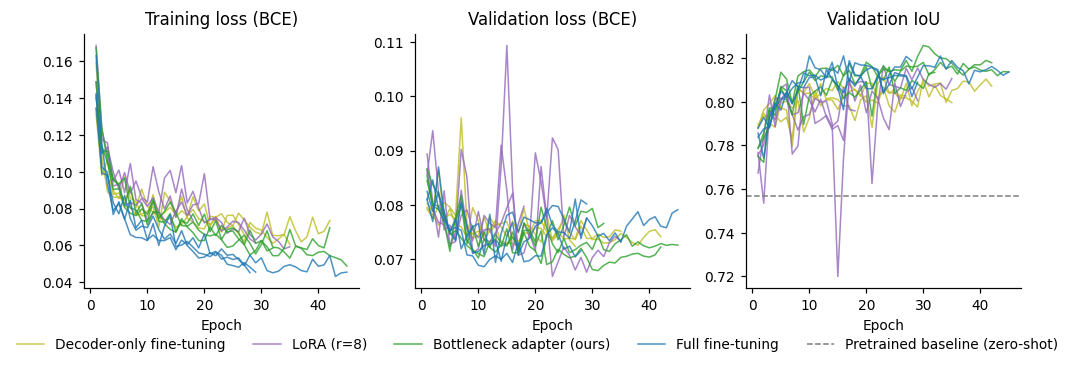

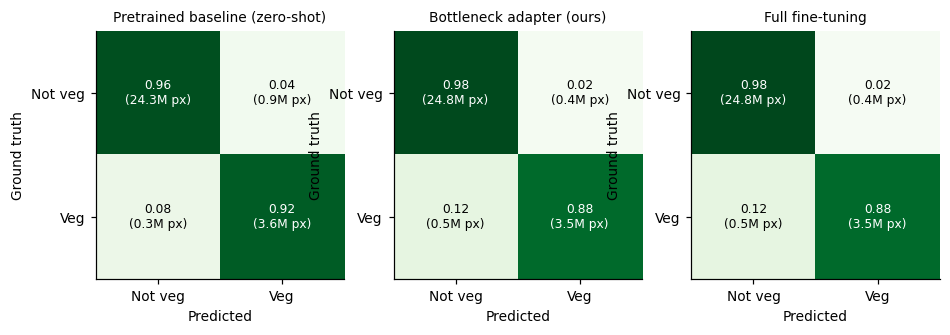

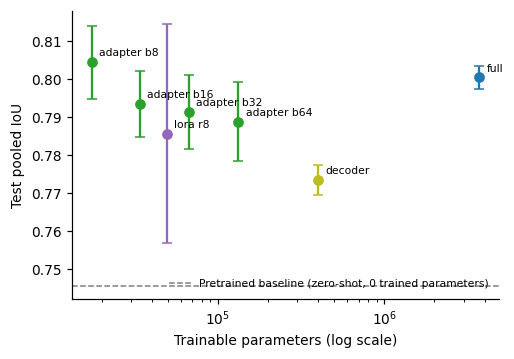

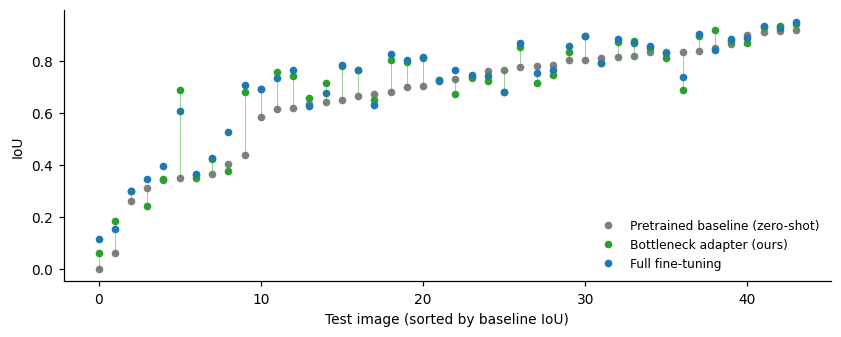

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

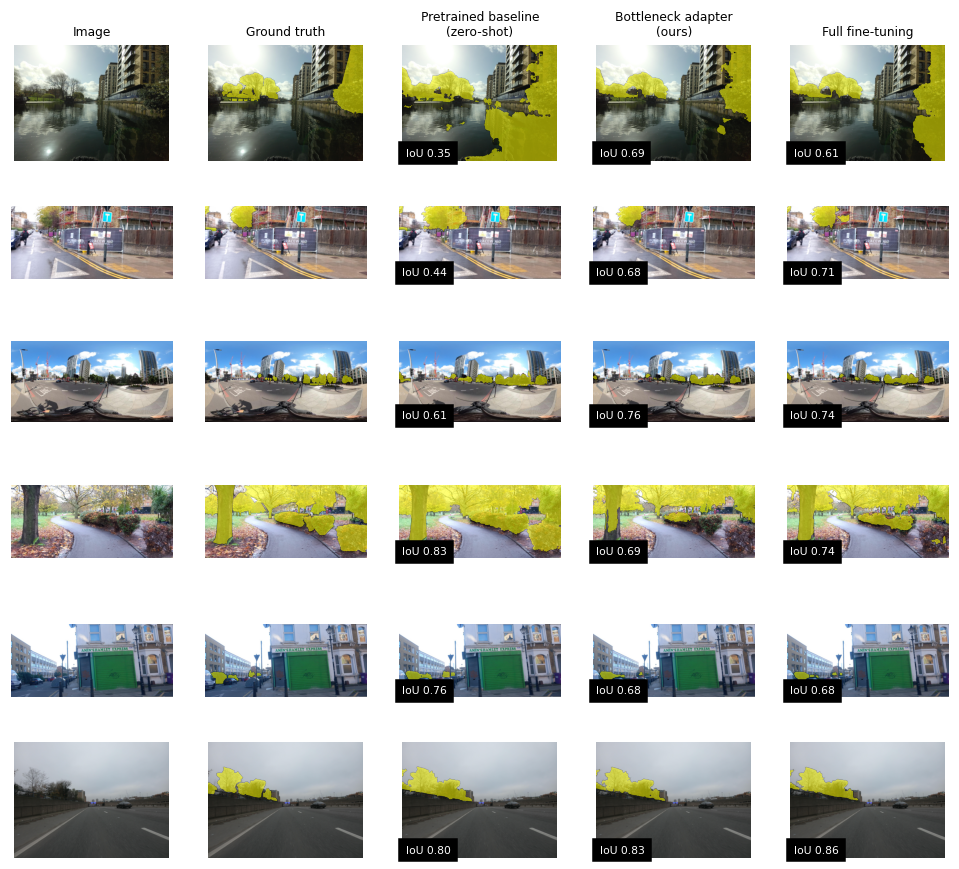

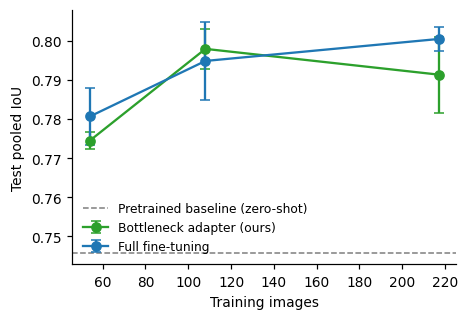

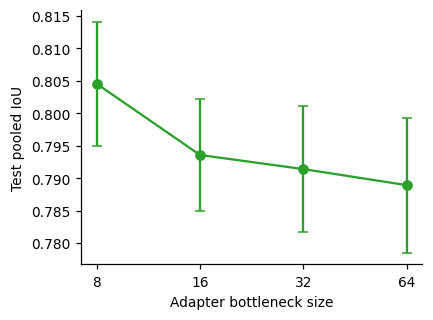

Figures saved to /content/drive/MyDrive/Dissertation/revision/results_v3/figures


In [ ]:
import matplotlib
matplotlib.use("Agg") if not IN_COLAB else None
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COL = {"zeroshot": "#7f7f7f", "decoder": "#bcbd22", "lora": "#9467bd", "adapter": "#2ca02c", "full": "#1f77b4"}

def save(fig, name):
    for ext in ["png", "pdf"]:
        fig.savefig(f"{RESULTS}/figures/{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show() if IN_COLAB else None
    plt.close(fig)

# F1: training loss and validation IoU per epoch (all seeds)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for m in ["decoder", "lora", "adapter", "full"]:
    for i, r in enumerate(final_runs(m)):
        h = pd.read_csv(f"{RESULTS}/runs/{r['run_id']}/history.csv")
        lab = NICE[m] if i == 0 else None
        ax[0].plot(h.epoch, h.train_loss, color=COL[m], alpha=.8, lw=1, label=lab)
        ax[1].plot(h.epoch, h.val_loss, color=COL[m], alpha=.8, lw=1)
        ax[2].plot(h.epoch, h.val_pooled_iou, color=COL[m], alpha=.8, lw=1)
zs = final_runs("zeroshot")
if zs: ax[2].axhline(zs[0]["val"]["argmax"]["pooled_iou"], color=COL["zeroshot"], ls="--", lw=1, label=NICE["zeroshot"])
for a, t in zip(ax, ["Training loss (BCE)", "Validation loss (BCE)", "Validation IoU"]):
    a.set_title(t); a.set_xlabel("Epoch")
fig.legend(loc="lower center", ncol=5, bbox_to_anchor=(.5, -.12), frameon=False)
save(fig, "F_training_curves")

# F2: pixel confusion matrices (test, pooled over images, mean over seeds)
ms = [m for m in ["zeroshot", "adapter", "full"] if f"tp_{m}" in PI]
fig, ax = plt.subplots(1, len(ms), figsize=(3.3 * len(ms), 3))
ax = np.atleast_1d(ax)
for a, m in zip(ax, ms):
    tp, fp, fn = PI[f"tp_{m}"].sum(), PI[f"fp_{m}"].sum(), PI[f"fn_{m}"].sum()
    tn = sum(r["n_pix"] for r in [dict(n_pix=RECS[i]["mask"].size) for i in PI.image_id]) - tp - fp - fn
    cm = np.array([[tn, fp], [fn, tp]], float)
    cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Greens", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j] / 1e6:.1f}M px)", ha="center", va="center",
                   color="white" if cmn[i, j] > .6 else "black", fontsize=8)
    a.set_xticks([0, 1], ["Not veg", "Veg"]); a.set_yticks([0, 1], ["Not veg", "Veg"])
    a.set_xlabel("Predicted"); a.set_ylabel("Ground truth"); a.set_title(NICE[m], fontsize=9)
save(fig, "F_confusion_matrices")

# F3: accuracy vs trainable parameters
fig, ax = plt.subplots(figsize=(5, 3.4))
pts = []
for r in RUNS:
    if r["spec"]["data"] != "full" or r["spec"]["method"] == "zeroshot": continue
    m = r["spec"]["method"]
    if r["spec"]["lr"] != chosen_lr(m): continue
    pts.append(dict(key=config_key(r), m=m, p=r["params"]["trainable_params"], iou=r["test"]["sig@0.5"]["pooled_iou"]))
pts = pd.DataFrame(pts)
if len(pts):
    for k, g in pts.groupby("key"):
        m = g.m.iloc[0]
        ax.errorbar(g.p.iloc[0], g.iou.mean(), yerr=g.iou.std(ddof=1) if len(g) > 1 else 0, fmt="o", color=COL[m], capsize=3)
        ax.annotate(k.replace("_", " "), (g.p.iloc[0], g.iou.mean()), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("Trainable parameters (log scale)"); ax.set_ylabel("Test pooled IoU")
if zs:
    ax.axhline(zs[0]["test"]["argmax"]["pooled_iou"], color=COL["zeroshot"], ls="--", lw=1, label="Pretrained baseline (zero-shot, 0 trained parameters)")
    ax.legend(frameon=False, fontsize=7, loc="lower right")
save(fig, "F_iou_vs_trainable_params")

# F4: per-image IoU, baseline vs adapter vs full (consistency of the improvement across images)
if {"iou_zeroshot", "iou_adapter"} <= set(PI.columns):
    d = PI.dropna(subset=["iou_zeroshot"]).sort_values("iou_zeroshot").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for m in [m for m in ["zeroshot", "adapter", "full"] if f"iou_{m}" in d]:
        ax.plot(d.index, d[f"iou_{m}"], "o", ms=4, color=COL[m], label=NICE[m])
    for i, row in d.iterrows():
        ax.plot([i, i], [row.iou_zeroshot, row.iou_adapter], color=COL["adapter"], lw=.6, alpha=.5)
    ax.set_xlabel("Test image (sorted by baseline IoU)"); ax.set_ylabel("IoU"); ax.legend(frameon=False, fontsize=8)
    save(fig, "F_per_image_iou")

# F5: qualitative examples: image | ground truth | baseline | adapter | full
def predict_mask(method):
    rs = final_runs(method)
    if not rs: return None
    r = rs[0]
    model, _ = build_model(r["spec"])
    if method != "zeroshot":
        model.load_state_dict(torch.load(f"{RESULTS}/runs/{r['run_id']}/best.pt", map_location="cpu"), strict=False)
    model.eval(); out = {}
    with torch.no_grad():
        for iid in PI.image_id:
            x = eval_tensor(RECS[iid]["img"]).to(DEVICE)
            lg = veg_logits(model, x)[0].float()
            out[iid] = (lg.argmax(0) == CFG["veg_class"]).cpu().numpy() if method == "zeroshot" else (torch.sigmoid(lg[CFG["veg_class"]]) > .5).cpu().numpy()
    del model
    return out

if {"iou_zeroshot", "iou_adapter"} <= set(PI.columns):
    MASKS = {m: predict_mask(m) for m in ["zeroshot", "adapter", "full"]}
    d = PI[PI.gt_pct > 1].copy(); d["gain"] = d.iou_adapter - d.iou_zeroshot
    pick = list(d.nlargest(3, "gain").image_id) + list(d.nsmallest(2, "gain").image_id) + [d.sort_values("gt_pct").image_id.iloc[len(d) // 2]]
    pick = list(dict.fromkeys(pick))          # 3 biggest gains, 2 biggest losses, 1 typical image (no duplicates)
    cols = ["Image", "Ground truth"] + [NICE[m] for m in MASKS if MASKS[m] is not None]
    fig, ax = plt.subplots(len(pick), len(cols), figsize=(2.2 * len(cols), 1.6 * len(pick)))
    for i, iid in enumerate(pick):
        R = RECS[iid]; panels = [R["img"], R["mask"]] + [MASKS[m][iid] for m in MASKS if MASKS[m] is not None]
        for j, p in enumerate(panels):
            a = ax[i, j]; a.axis("off")
            if j == 0: a.imshow(p)
            else:
                a.imshow(R["img"]); a.imshow(np.ma.masked_where(p == 0, p), cmap="autumn", alpha=.55, vmin=0, vmax=1)
            if i == 0: a.set_title(cols[j].replace(" (", "\n("), fontsize=8)
            if j >= 2:
                m = list(MASKS)[j - 2]; a.text(.02, .04, f"IoU {PI.set_index('image_id').loc[iid, f'iou_{m}']:.2f}", color="white", fontsize=7, backgroundcolor="black", transform=a.transAxes)
    save(fig, "F_qualitative_examples")

# F6/F7: extras
if "T_data_efficiency" in EXTRA_T:
    t = EXTRA_T["T_data_efficiency"]; fig, ax = plt.subplots(figsize=(4.5, 3))
    for m, g in t.groupby("method"):
        key = [k for k, v in NICE.items() if v == m][0]
        g = g.sort_values("train_fraction"); ax.errorbar(g.n_train, g.test_pooled_iou_mean, yerr=g.sd, marker="o", capsize=3, color=COL[key], label=m)
    if zs: ax.axhline(zs[0]["test"]["argmax"]["pooled_iou"], color=COL["zeroshot"], ls="--", lw=1, label=NICE["zeroshot"])
    ax.set_xlabel("Training images"); ax.set_ylabel("Test pooled IoU"); ax.legend(frameon=False, fontsize=8)
    save(fig, "F_data_efficiency")
if "T_bottleneck_ablation" in EXTRA_T:
    t = EXTRA_T["T_bottleneck_ablation"]; fig, ax = plt.subplots(figsize=(4, 3))
    ax.errorbar(t.bottleneck, t.test_pooled_iou_mean, yerr=t.sd.fillna(0), marker="o", capsize=3, color=COL["adapter"])
    ax.set_xscale("log", base=2); ax.set_xticks(t.bottleneck, t.bottleneck); ax.set_xlabel("Adapter bottleneck size"); ax.set_ylabel("Test pooled IoU")
    save(fig, "F_bottleneck_ablation")
print("Figures saved to", f"{RESULTS}/figures")

## 10. Reconciling the dissertation numbers (0.564 vs 0.586)
Scores the original 31 validation images with the unified evaluator: zero-shot with both decision rules, and the
dissertation adapter (`best_adapters_v2.pt`). This explains how the old numbers relate to the new ones.
Note: the dissertation adapter was trained on 432×432 stretched images, so these images are slightly out of its
training distribution, and most of the new test images were in its training set, so it is **not** evaluated on the new test set.

In [ ]:
def legacy_reconciliation():
    if not os.path.exists(CFG["legacy_adapter"]):
        print("best_adapters_v2.pt not found at", CFG["legacy_adapter"], "- skipping."); return None
    old_val = [RECS[i] for i in full_split[full_split.original_split == "valid"].image_id if i in RECS]
    if not old_val:
        print("No original validation images loaded - skipping."); return None
    rows = []
    zs_model, _ = build_model(dict(method="zeroshot"))
    ev = evaluate(zs_model, old_val)
    for name, rule in [("argmax", "argmax"), ("sigmoid > 0.5", 0.5)]:
        s = summarise(counts(ev, rule)); c = counts(ev, rule)
        rows.append(dict(model="Pretrained baseline", rule=name, old_convention_mean_iou=c.iou.fillna(1.0).mean(), **{k: s[k] for k in ["pooled_iou", "mean_image_iou"]}))
    del zs_model
    ad, _ = build_model(dict(method="adapter", bottleneck=32))
    sd = torch.load(CFG["legacy_adapter"], map_location="cpu")
    missing, unexpected = ad.adapters.load_state_dict(sd, strict=True), None
    ev = evaluate(ad, old_val)
    for name, rule in [("argmax", "argmax"), ("sigmoid > 0.5", 0.5)]:
        s = summarise(counts(ev, rule)); c = counts(ev, rule)
        rows.append(dict(model="Dissertation adapter (best_adapters_v2.pt)", rule=name, old_convention_mean_iou=c.iou.fillna(1.0).mean(), **{k: s[k] for k in ["pooled_iou", "mean_image_iou"]}))
    t = pd.DataFrame(rows)
    t.insert(0, "n_images", len(old_val))
    t.to_csv(f"{RESULTS}/tables/T_legacy_reconciliation.csv", index=False)
    print("Dissertation reported: baseline 0.564 (argmax, old convention), adapter 0.586 (sigmoid > 0.5, old convention)")
    print("'old_convention_mean_iou' = mean per-image IoU with empty images scored 1.0, as in the dissertation code")
    print(t.round(4).to_string(index=False))
    return t
T_LEGACY = legacy_reconciliation()

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Dissertation reported: baseline 0.564 (argmax, old convention), adapter 0.586 (sigmoid > 0.5, old convention)
'old_convention_mean_iou' = mean per-image IoU with empty images scored 1.0, as in the dissertation code
 n_images                                      model          rule  old_convention_mean_iou  pooled_iou  mean_image_iou
       31                        Pretrained baseline        argmax                   0.5276      0.6522          0.5640
       31                        Pretrained baseline sigmoid > 0.5                   0.5201      0.6514          0.5560
       31 Dissertation adapter (best_adapters_v2.pt)        argmax                   0.5472      0.6814          0.5849
       31 Dissertation adapter (best_adapters_v2.pt) sigmoid > 0.5                   0.5464      0.6815          0.5841


## 11. Summary
Everything above is saved in `results_v3/` on Drive (`tables/` and `figures/`).

In [ ]:
summary = dict(main=T_MAIN.to_dict("records"), significance=T_STATS.to_dict("records"), leakage=LEAK.to_dict("records"),
               chosen_lr={m: chosen_lr(m) for m in CFG["lr_grid"]}, env=ENV, n_runs=len(RUNS))
json.dump(summary, open(f"{RESULTS}/SUMMARY.json", "w"), indent=2, default=str)
if IN_COLAB:
    pack = f"{WORK}/pack_results"; shutil.rmtree(pack, ignore_errors=True)     # tables + figures only (no model weights)
    for sub in ["tables", "figures"]: shutil.copytree(f"{RESULTS}/{sub}", f"{pack}/{sub}")
    for f in ["SUMMARY.json", "environment_and_config.json"]: shutil.copy(f"{RESULTS}/{f}", pack)
    shutil.make_archive(f"{WORK}/results_v3_tables_figures", "zip", pack)
    print("Zipped results:", f"{WORK}/results_v3_tables_figures.zip")
    from google.colab import files
    files.download(f"{WORK}/results_v3_tables_figures.zip")
print("DONE. Runs completed:", len(RUNS))

Zipped results: /content/work/results_v3_tables_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DONE. Runs completed: 68
